# SQL Playground
DuckDB + Jupyter. Everything you create is stored in `work/playground.duckdb` and survives restarts.

1. Define a schema with SQL → draw the ER diagram
2. Or draw the ER diagram as text (Mermaid) → get the schema generated
3. Play with queries

In [1]:
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
import erplay
con = erplay.connect("playground")
%sql con

## 1. Schema with SQL
Re-running this cell is safe: it starts with a clean database.

In [2]:
erplay.reset(con)

In [3]:
%%sql
CREATE TABLE student (
    id    INTEGER PRIMARY KEY,
    name  VARCHAR NOT NULL,
    class VARCHAR
);
CREATE TABLE teacher (
    id   INTEGER PRIMARY KEY,
    name VARCHAR NOT NULL
);
CREATE TABLE course (
    id         INTEGER PRIMARY KEY,
    title      VARCHAR NOT NULL,
    teacher_id INTEGER REFERENCES teacher(id)
);
CREATE TABLE enrollment (
    student_id INTEGER REFERENCES student(id),
    course_id  INTEGER REFERENCES course(id),
    grade      INTEGER CHECK (grade BETWEEN 1 AND 6),
    PRIMARY KEY (student_id, course_id)
);

,Count


In [4]:
%%sql
INSERT INTO student VALUES (1,'Anna','10a'),(2,'Ben','10a'),(3,'Chris','10b');
INSERT INTO teacher VALUES (1,'Ms Meyer'),(2,'Mr Schulz');
INSERT INTO course VALUES (1,'Math',1),(2,'Physics',2),(3,'Art',NULL);
INSERT INTO enrollment VALUES (1,1,2),(1,2,1),(2,1,3),(3,3,2);

,Count


## 2. ER diagram of the current database

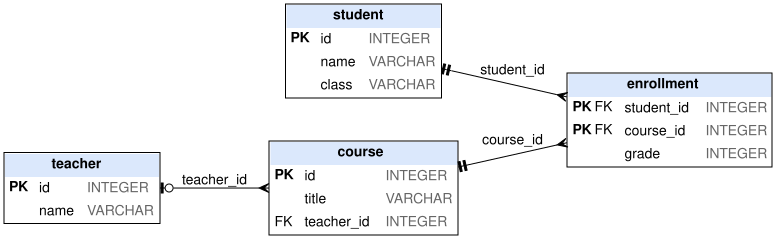

In [5]:
erplay.er_diagram(con)

The same schema as editable Mermaid text. Paste it into the `er-to-schema.ipynb` notebook to go the other way (diagram → tables), or into any Mermaid renderer such as mermaid.live:

In [6]:
print(erplay.schema_to_mermaid(con))

erDiagram
    teacher |o--o{ course : has
    student ||--o{ enrollment : has
    course ||--o{ enrollment : has
    course {
        INTEGER id PK
        VARCHAR title
        INTEGER teacher_id FK
    }
    enrollment {
        INTEGER student_id PK, FK
        INTEGER course_id PK, FK
        INTEGER grade
    }
    student {
        INTEGER id PK
        VARCHAR name
        VARCHAR class
    }
    teacher {
        INTEGER id PK
        VARCHAR name
    }


## 3. Queries

In [7]:
%%sql
SELECT s.name AS student, c.title AS course, e.grade
FROM enrollment e
JOIN student s ON s.id = e.student_id
JOIN course  c ON c.id = e.course_id
ORDER BY s.name;

,student,course,grade
0,Anna,Physics,1
1,Anna,Math,2
2,Ben,Math,3
3,Chris,Art,2


In [8]:
%%sql
-- average grade per course, including courses nobody takes
SELECT c.title, round(avg(e.grade), 2) AS avg_grade, count(e.student_id) AS students
FROM course c LEFT JOIN enrollment e ON e.course_id = c.id
GROUP BY c.title
ORDER BY avg_grade;

,title,avg_grade,students
0,Physics,1.0,1
1,Art,2.0,1
2,Math,2.5,2


Your turn: write your own queries below.

In [9]:
%%sql
-- your query here
SELECT * FROM student;

,id,name,class
0,1,Anna,10a
1,2,Ben,10a
2,3,Chris,10b


➡️ To generate tables from an ER diagram, open **`er-to-schema.ipynb`**.